# Wine Quality Prediction

ANA680 Assignment 5, Problem 1
Jesus Adrian Alvarado Gadea

This notebook builds the model for the Docker app in this folder. It uses the UCI Wine Quality data (red and white vinho verde wines) to predict a wine's quality score (0 to 10) from its 11 physicochemical measurements.

In [1]:
import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import KFold, cross_val_score, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

## Load the data

Both UCI files are used. Wine color is not one of the 11 features in the assignment, so it is not used as an input.

In [2]:
# The UCI files use semicolons as separators
red = pd.read_csv("winequality-red.csv", sep=";")
white = pd.read_csv("winequality-white.csv", sep=";")
wine = pd.concat([red, white], ignore_index=True)

print("Red wines:", len(red), "| White wines:", len(white), "| Total:", len(wine))
wine.head()

Red wines: 1599 | White wines: 4898 | Total: 6497


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


## Clean the data

In [3]:
print("Missing values:", wine.isna().sum().sum())
print("Duplicate rows:", wine.duplicated().sum())

# Remove exact duplicates so the same wine can't end up in both the training and test sets
wine = wine.drop_duplicates().reset_index(drop=True)
print("Wines after removing duplicates:", len(wine))

Missing values: 0
Duplicate rows: 1179
Wines after removing duplicates: 5318


## Explore the data

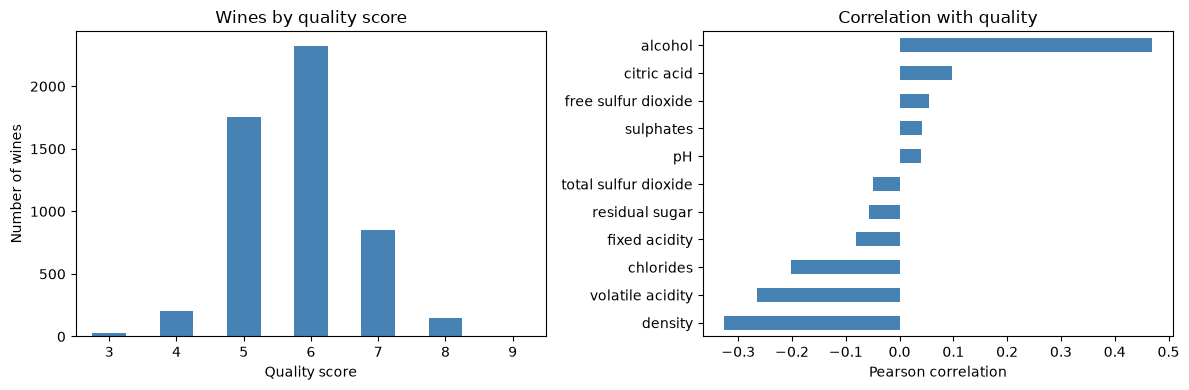

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

wine["quality"].value_counts().sort_index().plot.bar(ax=axes[0], color="steelblue", rot=0)
axes[0].set(title="Wines by quality score", xlabel="Quality score", ylabel="Number of wines")

wine.corr()["quality"].drop("quality").sort_values().plot.barh(ax=axes[1], color="steelblue")
axes[1].set(title="Correlation with quality", xlabel="Pearson correlation")

plt.tight_layout()
plt.show()

Most wines score 5, 6, or 7, and very few score 3 or 9. Alcohol has the strongest link with quality (higher alcohol, higher score), followed by density, volatile acidity, and chlorides (higher values, lower score). The other measurements are only weakly related to quality on their own.

## Split the data

In [5]:
FEATURES = wine.columns.drop("quality").tolist()
X = wine[FEATURES].to_numpy()
y = wine["quality"].to_numpy()

# 80% training data and 20% test data, with the same mix of quality scores in both
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)
print("Training wines:", len(X_train), "| Test wines:", len(X_test))

Training wines: 4254 | Test wines: 1064


## Compare algorithms

Each algorithm is scored with 5-fold cross-validation on the training data, using the root mean squared error (RMSE) of the predicted score. Lower is better.

In [6]:
candidates = {
    "Linear Regression": make_pipeline(StandardScaler(), LinearRegression()),
    "Random Forest": RandomForestRegressor(n_estimators=200, max_features="sqrt", random_state=42),
    "Gradient Boosting": HistGradientBoostingRegressor(random_state=42),
}
cv = KFold(n_splits=5, shuffle=True, random_state=42)

results = {}
for name, model in candidates.items():
    scores = cross_val_score(model, X_train, y_train, cv=cv, scoring="neg_root_mean_squared_error")
    results[name] = -scores.mean()

pd.Series(results, name="Cross-validation RMSE").sort_values().round(4).to_frame()

,Cross-validation RMSE
Random Forest,0.6879
Gradient Boosting,0.7025
Linear Regression,0.7357


## Train and test the best model

In [7]:
best_name = min(results, key=results.get)
model = candidates[best_name].fit(X_train, y_train)

pred = model.predict(X_test)
score = np.clip(np.rint(pred), 0, 10)  # whole-number quality score shown in the app
baseline = np.full(len(y_test), y_train.mean())  # always guessing the average score

print("Selected model:", best_name)
print(f"Test RMSE {mean_squared_error(y_test, pred) ** 0.5:.3f} (always guessing the average: {mean_squared_error(y_test, baseline) ** 0.5:.3f})")
print(f"Test MAE  {mean_absolute_error(y_test, pred):.3f}")
print(f"Test R2   {r2_score(y_test, pred):.3f}")
print(f"Exact score after rounding: {np.mean(score == y_test):.1%}")
print(f"Within one point:           {np.mean(np.abs(score - y_test) <= 1):.1%}")

Selected model: Random Forest
Test RMSE 0.682 (always guessing the average: 0.880)
Test MAE  0.528
Test R2   0.400
Exact score after rounding: 55.5%
Within one point:           97.6%


Random Forest has the lowest cross-validation error, so it is the final model. On the test wines its estimate is off by about half a point on average. After rounding, it gives the exact score for a little over half of the wines and is within one point for almost all of them. That is a clear improvement over always guessing the average score, but quality is a subjective rating, and the 11 measurements explain only about 40% of its variation (R2 of 0.40).

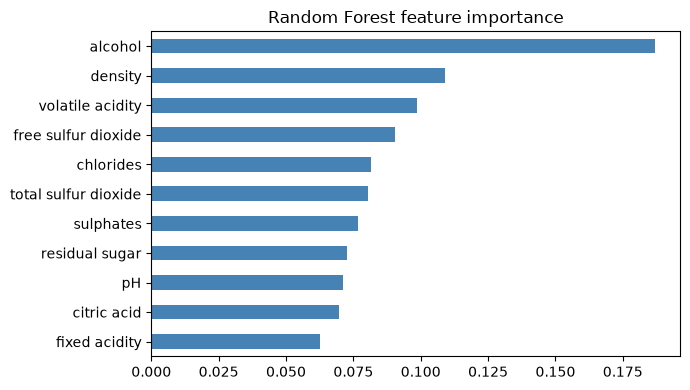

In [8]:
# Which measurements the model relies on most
importance = pd.Series(model.feature_importances_, index=FEATURES).sort_values()
importance.plot.barh(figsize=(7, 4), color="steelblue", title=f"{best_name} feature importance")
plt.tight_layout()
plt.show()

## Save the model

The Flask app in this folder loads `model.joblib`. Compression keeps the file small enough for GitHub and the container image.

In [9]:
joblib.dump(model, "model.joblib", compress=3)

# Reload the saved file and predict the first red wine in the dataset (the app's example wine)
loaded = joblib.load("model.joblib")
example = red[FEATURES].iloc[[0]].to_numpy()
print(dict(zip(FEATURES, example[0].tolist())))
print(f"Predicted quality {loaded.predict(example)[0]:.2f} (actual {red['quality'].iloc[0]})")

{'fixed acidity': 7.4, 'volatile acidity': 0.7, 'citric acid': 0.0, 'residual sugar': 1.9, 'chlorides': 0.076, 'free sulfur dioxide': 11.0, 'total sulfur dioxide': 34.0, 'density': 0.9978, 'pH': 3.51, 'sulphates': 0.56, 'alcohol': 9.4}
Predicted quality 5.04 (actual 5)
